# 03 — Methods Demo: Query Engine, Anomaly Detection & Clustering

This notebook **explains and runs** the three analytical components, by importing the `src` modules. The modules stay as reusable `.py` files (so they can be tested and reused by the future RAG/interface layers); this notebook is the *documented, interactive* view of them.

> **Kernel:** pick **Python (tshci - time_series_hci)**.

## Contents
- Setup (load + preprocess)
- **A. Query engine** — the exact, deterministic *truth layer*
- **B. Anomaly detection** — residual z-score vs Isolation Forest
- **C. Clustering** — grouping day-types

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_repo():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base / "data" / "jena_climate_2009_2016.csv").exists():
            return base
    raise FileNotFoundError("Run from inside the repo.")

ROOT = find_repo()
sys.path.insert(0, str(ROOT / "v1"))            # make `src` importable
from src import preprocess, analysis, anomaly, clustering, query_engine as qe

df = preprocess.align(preprocess.clean(preprocess.load_data(ROOT / "data" / "jena_climate_2009_2016.csv")), freq="1h")
SENSOR = "T (degC)"
print(f"Ready: {len(df):,} hourly rows, {df.shape[1]} sensors.")

Ready: 70,129 hourly rows, 14 sensors.


## A. Query engine — the truth layer

**What it is:** a set of plain Python functions in `src/query_engine.py` that compute *exact* answers straight from the data — max, min, mean, std, correlation, missing counts, anomaly windows.

**Why it exists:** an LLM can sound confident and still invent a number. So the rule is **the LLM never calculates** — these functions do, and the LLM only explains their output. Every function returns a *structured* result (value + sensor + timestamp) so the explanation layer has everything it needs without recomputing.

Below: a full summary of the temperature sensor.

In [2]:
summary = qe.sensor_summary(df, SENSOR)
for k, v in summary.items():
    print(f"{k:>8}: {v}")

  sensor: T (degC)
    mean: 9.444727092215773
     std: 8.409740076707907
     min: -22.653333333333336
     max: 37.038333333333334
   range: 59.69166666666667
 missing: 0
  max_at: 2015-07-04 16:00:00
  min_at: 2009-01-07 03:00:00


In [3]:
# Individual queries return structured objects, not just numbers
hottest = qe.get_max(df, SENSOR)
print(f"Hottest: {hottest.value:.2f} degC at {hottest.when}")
print(f"corr(T, air density) = {qe.get_correlation(df, SENSOR, 'rho (g/m**3)'):.3f}")

# The trust guarantee: identical to pandas computed independently
assert hottest.value == df[SENSOR].max() and hottest.when == df[SENSOR].idxmax()
print("\nVerified: query engine == pandas ground truth (exact).")

Hottest: 37.04 degC at 2015-07-04 16:00:00
corr(T, air density) = -0.963

Verified: query engine == pandas ground truth (exact).


## B. Anomaly detection

**Goal:** flag readings that are *unusual* — sensor glitches or genuine extreme events. Two complementary methods (both in `src/anomaly.py`):

1. **Residual z-score (baseline).** Temperature is dominated by season + day/night. We first **STL-decompose** it into trend + seasonal + residual, then z-score the *residual*. This asks: *given the time of year and day, was this reading surprising?* — far better than z-scoring the raw value (a 25 °C day is normal in July, abnormal in January).
2. **Isolation Forest (multi-sensor).** An unsupervised ML model that isolates points needing few random splits to separate. Run across *all* sensors, it flags unusual **combinations** (e.g. a temperature/humidity/pressure mix that never normally co-occurs).

In [4]:
# 1) decompose temperature, then z-score the residual
decomp = analysis.decompose(df[SENSOR], period=24)   # 24 hourly steps = one daily cycle
resid_anom = anomaly.zscore_anomalies(decomp["resid"].dropna(), threshold=4.0)

# 2) Isolation Forest across all sensors
iforest = anomaly.isolation_forest_anomalies(df, contamination=0.01)

common = resid_anom.index.intersection(iforest.index)
ra = resid_anom.reindex(common).fillna(False)
ifo = iforest.reindex(common).fillna(False)
print(f"Residual z-score : {ra.sum():>4} anomalies ({100*ra.mean():.2f}%)")
print(f"Isolation Forest : {ifo.sum():>4} anomalies ({100*ifo.mean():.2f}%)")
print(f"Agree on         : {(ra & ifo).sum()} points")

Residual z-score :  526 anomalies (0.75%)
Isolation Forest :  702 anomalies (1.00%)
Agree on         : 33 points


In [5]:
# Are flagged points really extreme? Compare residual magnitudes.
print(f"mean |residual|, flagged : {decomp.loc[ra[ra].index, 'resid'].abs().mean():.2f} degC")
print(f"mean |residual|, overall : {decomp['resid'].abs().mean():.2f} degC")

# Collapse individual flags into readable intervals (what the query engine returns)
windows = qe.get_anomaly_windows(ra)
print(f"\n{len(windows)} anomaly windows; first few:")
for w in windows[:5]:
    print(f"  {w['start']} -> {w['end']}  ({w['n_points']} pts)")

mean |residual|, flagged : 8.09 degC
mean |residual|, overall : 1.00 degC

166 anomaly windows; first few:
  2009-01-07 03:00:00 -> 2009-01-07 13:00:00  (11 pts)
  2009-01-14 07:00:00 -> 2009-01-14 09:00:00  (3 pts)
  2009-01-14 15:00:00 -> 2009-01-14 15:00:00  (1 pts)
  2009-02-19 03:00:00 -> 2009-02-19 07:00:00  (5 pts)
  2009-04-05 10:00:00 -> 2009-04-05 10:00:00  (1 pts)


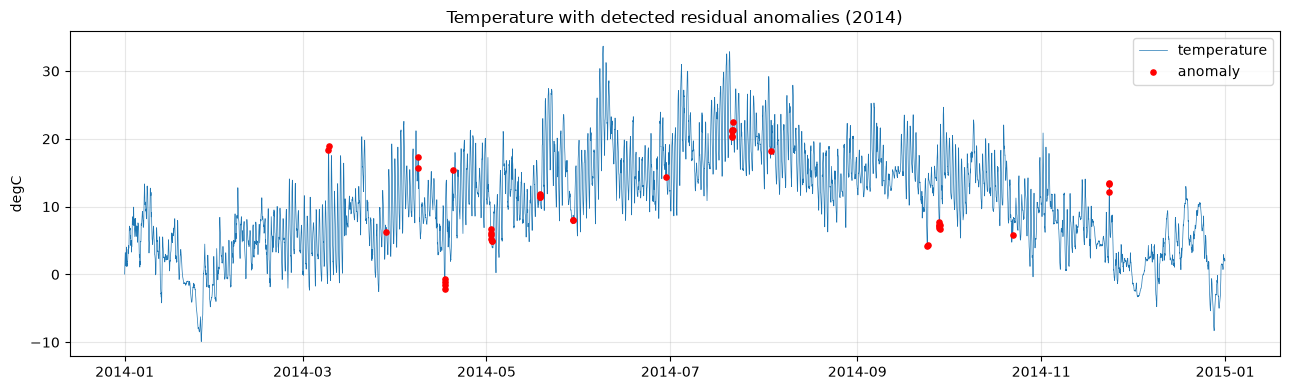

In [6]:
# Visualise one year with residual anomalies marked
year = df.loc["2014", SENSOR]
ya = ra.reindex(year.index).fillna(False)
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(year.index, year.values, linewidth=0.5, label="temperature")
ax.scatter(year.index[ya], year[ya], color="red", s=14, zorder=3, label="anomaly")
ax.set_title("Temperature with detected residual anomalies (2014)")
ax.set_ylabel("degC"); ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

## C. Clustering — day-types

**Goal:** group *similar periods* together without labels. We summarise each calendar day into a feature vector (mean/std/min/max of every sensor) via `clustering.daily_features`, then run **K-means** (`k=4`). Looking at each cluster's mean temperature tells us what it represents — we expect a cold→warm gradient matching the seasons.

In [7]:
feats = clustering.daily_features(df)
labels = clustering.kmeans_cluster(feats, k=4)
profiles = clustering.cluster_profiles(feats, labels)

table = pd.DataFrame({
    "n_days": labels.value_counts().sort_index(),
    "mean_temp": profiles[f"mean_{SENSOR}"].round(1),
    "mean_humidity": profiles["mean_rh (%)"].round(1),
}).sort_values("mean_temp")
print("Day-types (cold -> warm):")
table

Day-types (cold -> warm):


,n_days,mean_temp,mean_humidity
cluster,,,
1,849,0.5,84.0
0,492,6.5,75.6
3,960,12.2,74.4
2,621,19.6,68.0


### Reading the result
The clusters line up as a temperature gradient — cold/humid winter days at one end, warm summer days at the other — confirming K-means recovers meaningful seasonal day-types. This is the basis for *cluster-based* reasoning later: "this day behaves like a typical cold-winter day."